In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA 

In [4]:
df = pd.read_csv('sales_data_sample.csv' , encoding='unicode_escape' )

df.head()

,ORDERNUMBER,QUANTITYORDERED,PRICEEACH,ORDERLINENUMBER,SALES,ORDERDATE,STATUS,QTR_ID,MONTH_ID,YEAR_ID,...,ADDRESSLINE1,ADDRESSLINE2,CITY,STATE,POSTALCODE,COUNTRY,TERRITORY,CONTACTLASTNAME,CONTACTFIRSTNAME,DEALSIZE
0,10107,30,95.70,2,2871.00,2/24/2003 0:00,Shipped,1,2,2003,...,897 Long Airport Avenue,NaN,NYC,NY,10022,USA,NaN,Yu,Kwai,Small
1,10121,34,81.35,5,2765.90,5/7/2003 0:00,Shipped,2,5,2003,...,59 rue de l'Abbaye,NaN,Reims,NaN,51100,France,EMEA,Henriot,Paul,Small
2,10134,41,94.74,2,3884.34,7/1/2003 0:00,Shipped,3,7,2003,...,27 rue du Colonel Pierre Avia,NaN,Paris,NaN,75508,France,EMEA,Da Cunha,Daniel,Medium
3,10145,45,83.26,6,3746.70,8/25/2003 0:00,Shipped,3,8,2003,...,78934 Hillside Dr.,NaN,Pasadena,CA,90003,USA,NaN,Young,Julie,Medium
4,10159,49,100.00,14,5205.27,10/10/2003 0:00,Shipped,4,10,2003,...,7734 Strong St.,NaN,San Francisco,CA,NaN,USA,NaN,Brown,Julie,Medium


In [5]:
df.shape

(2823, 25)

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2823 entries, 0 to 2822
Data columns (total 25 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   ORDERNUMBER       2823 non-null   int64  
 1   QUANTITYORDERED   2823 non-null   int64  
 2   PRICEEACH         2823 non-null   float64
 3   ORDERLINENUMBER   2823 non-null   int64  
 4   SALES             2823 non-null   float64
 5   ORDERDATE         2823 non-null   str    
 6   STATUS            2823 non-null   str    
 7   QTR_ID            2823 non-null   int64  
 8   MONTH_ID          2823 non-null   int64  
 9   YEAR_ID           2823 non-null   int64  
 10  PRODUCTLINE       2823 non-null   str    
 11  MSRP              2823 non-null   int64  
 12  PRODUCTCODE       2823 non-null   str    
 13  CUSTOMERNAME      2823 non-null   str    
 14  PHONE             2823 non-null   str    
 15  ADDRESSLINE1      2823 non-null   str    
 16  ADDRESSLINE2      302 non-null    str    
 17  CITY  

In [19]:
print("\nMissing Values:")
print(df.isnull().sum())

print("\nStatistical Summary:")
print(df.describe())


Missing Values:
ORDERNUMBER            0
QUANTITYORDERED        0
PRICEEACH              0
ORDERLINENUMBER        0
SALES                  0
ORDERDATE              0
STATUS                 0
QTR_ID                 0
MONTH_ID               0
YEAR_ID                0
PRODUCTLINE            0
MSRP                   0
PRODUCTCODE            0
CUSTOMERNAME           0
PHONE                  0
ADDRESSLINE1           0
ADDRESSLINE2        2521
CITY                   0
STATE               1486
POSTALCODE            76
COUNTRY                0
TERRITORY           1074
CONTACTLASTNAME        0
CONTACTFIRSTNAME       0
DEALSIZE               0
dtype: int64

Statistical Summary:
        ORDERNUMBER  QUANTITYORDERED    PRICEEACH  ORDERLINENUMBER  \
count   2823.000000      2823.000000  2823.000000      2823.000000   
mean   10258.725115        35.092809    83.658544         6.466171   
std       92.085478         9.741443    20.174277         4.225841   
min    10100.000000         6.000000    26.

In [20]:
df.dropna(subset=['CUSTOMERNAME'] , inplace=True)

/var/folders/zs/vfn5k789363gmxvqm3wzwttw0000gn/T/ipykernel_82557/4076034778.py:1: Pandas4Warning: The inplace keyword in DataFrame.dropna is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.dropna(subset=['CUSTOMERNAME'] , inplace=True)


In [21]:
print(df.shape)


df['CUSTOMERNAME'].value_counts()

(2823, 25)


CUSTOMERNAME
Euro Shopping Channel           259
Mini Gifts Distributors Ltd.    180
Australian Collectors, Co.       55
La Rochelle Gifts                53
AV Stores, Co.                   51
                               ... 
Microscale Inc.                  10
Royale Belge                      8
Auto-Moto Classics Inc.           8
Atelier graphique                 7
Boards & Toys Co.                 3
Name: count, Length: 92, dtype: int64

In [22]:
customer_data = df.groupby('CUSTOMERNAME').agg({
    'SALES': 'sum',
    'QUANTITYORDERED': 'sum',
    'PRICEEACH': 'mean',
    'ORDERNUMBER': 'nunique'
})

customer_data.columns = [
    'Total_Sales',
    'Total_Quantity',
    'Average_Price',
    'Total_Orders'
]

print(customer_data.head())
print("\nCustomer Dataset Shape:", customer_data.shape)

                         Total_Sales  Total_Quantity  Average_Price  \
CUSTOMERNAME                                                          
AV Stores, Co.             157807.81            1778      77.947647   
Alpha Cognac                70488.44             687      85.097500   
Amica Models & Co.          94117.26             843      85.323462   
Anna's Decorations, Ltd    153996.13            1469      83.558043   
Atelier graphique           24179.96             270      79.775714   

                         Total_Orders  
CUSTOMERNAME                           
AV Stores, Co.                      3  
Alpha Cognac                        3  
Amica Models & Co.                  2  
Anna's Decorations, Ltd             4  
Atelier graphique                   3  

Customer Dataset Shape: (92, 4)


In [23]:
scaler = StandardScaler() 

X_scaled = scaler.fit_transform(customer_data) 

print("Scaled Data") 
print(X_scaled[:5])

Scaled Data
[[ 0.44443187  0.6360107  -1.75306058 -0.1158306 ]
 [-0.35149724 -0.35358247  0.34006081 -0.1158306 ]
 [-0.13611702 -0.21208244  0.40621111 -0.45958594]
 [ 0.40968783  0.35573179 -0.11061551  0.22792473]
 [-0.77360596 -0.73182294 -1.21789341 -0.1158306 ]]


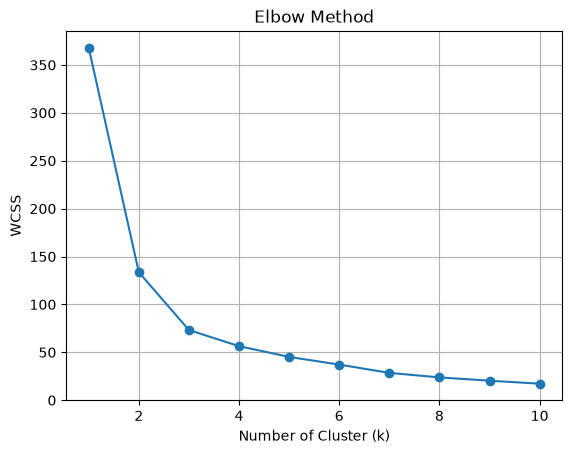

In [24]:
wcss = [] 

for i in range (1,11) :

    kmeans = KMeans(
        n_clusters=i,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_scaled) 

    wcss.append(kmeans.inertia_)


plt.plot(range(1,11) , wcss , marker='o') 
plt.title("Elbow Method")
plt.xlabel("Number of Cluster (k)")
plt.ylabel("WCSS")
plt.grid() 
plt.show()

In [25]:
k = 3 

kmeans = KMeans(
    n_clusters=k,
    random_state=42,
    n_init=10

)

customer_data['Cluster'] = kmeans.fit_predict(X_scaled) 

print("Customer Data Cluster :" , customer_data.head(10)) 


# print("Customer Cluster Count :" , customer_data['Cluster'].value_counts()) 

Customer Data Cluster :                               Total_Sales  Total_Quantity  Average_Price  \
CUSTOMERNAME                                                               
AV Stores, Co.                  157807.81            1778      77.947647   
Alpha Cognac                     70488.44             687      85.097500   
Amica Models & Co.               94117.26             843      85.323462   
Anna's Decorations, Ltd         153996.13            1469      83.558043   
Atelier graphique                24179.96             270      79.775714   
Australian Collectables, Ltd     64591.46             705      78.683043   
Australian Collectors, Co.      200995.41            1926      85.717818   
Australian Gift Network, Co      59469.12             545      84.736667   
Auto Assoc. & Cie.               64834.32             637      82.492222   
Auto Canal Petit                 93170.66            1001      81.067407   

                              Total_Orders  Cluster  
CUSTOMERN

In [26]:
print("Customer Cluster Count :" , customer_data['Cluster'].value_counts()) 

Customer Cluster Count : Cluster
2    48
0    42
1     2
Name: count, dtype: int64


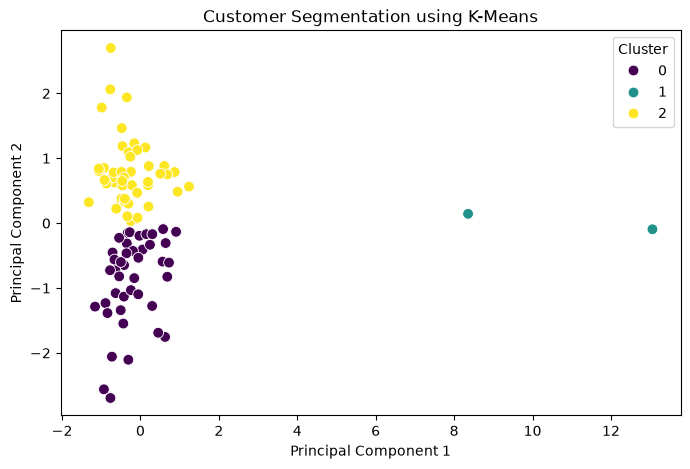

In [31]:
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)



plt.figure(figsize=(8, 5))

sns.scatterplot(
    x=X_pca[:, 0],
    y=X_pca[:, 1],
    hue=customer_data['Cluster'],
    palette='viridis',
    s=60
)

plt.title('Customer Segmentation using K-Means')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend(title='Cluster')
plt.show()

In [23]:
print(customer_data.groupby('Cluster').mean())

           Total_Sales  Total_Quantity  Average_Price  Total_Orders
Cluster                                                            
0         93903.546905      982.261905      80.983819      2.833333
1        783576.085000     7846.500000      82.575233     21.500000
2         94198.493958      877.479167      86.575652      3.020833
